In [1]:
import pandas as pd

df = pd.read_csv('Titanic-Dataset.csv')

numeric_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

# Combine standard describe() with median and skewness
summary = df[numeric_cols].describe().T
summary['median'] = df[numeric_cols].median()
summary['skewness'] = df[numeric_cols].skew()

print(summary[['count', 'mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness']].round(2))


          count   mean  median    std   min    25%    50%   75%     max  \
Survived  891.0   0.38    0.00   0.49  0.00   0.00   0.00   1.0    1.00   
Pclass    891.0   2.31    3.00   0.84  1.00   2.00   3.00   3.0    3.00   
Age       714.0  29.70   28.00  14.53  0.42  20.12  28.00  38.0   80.00   
SibSp     891.0   0.52    0.00   1.10  0.00   0.00   0.00   1.0    8.00   
Parch     891.0   0.38    0.00   0.81  0.00   0.00   0.00   0.0    6.00   
Fare      891.0  32.20   14.45  49.69  0.00   7.91  14.45  31.0  512.33   

          skewness  
Survived      0.48  
Pclass       -0.63  
Age           0.39  
SibSp         3.70  
Parch         2.75  
Fare          4.79  


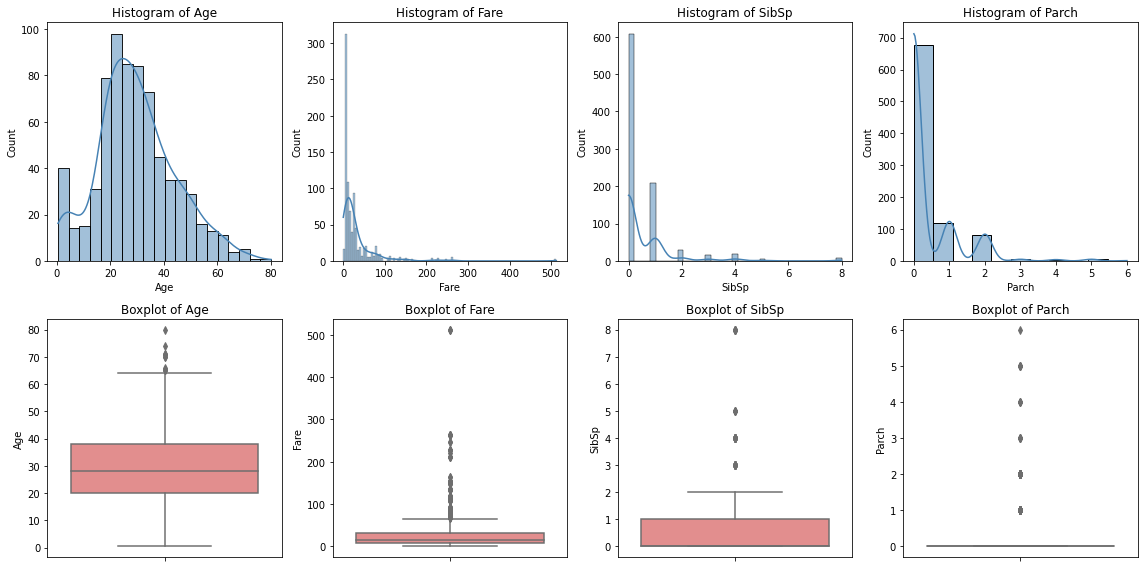

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_cols = ['Age', 'Fare', 'SibSp', 'Parch']
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, col in enumerate(plot_cols):
    # Top row: Histograms with KDE curve
    sns.histplot(df[col].dropna(), kde=True, ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'Histogram of {col}')
    
    # Bottom row: Boxplots
    sns.boxplot(y=df[col].dropna(), ax=axes[1, i], color='lightcoral')
    axes[1, i].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

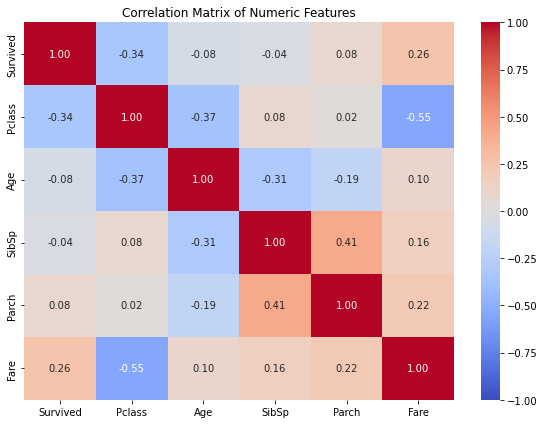

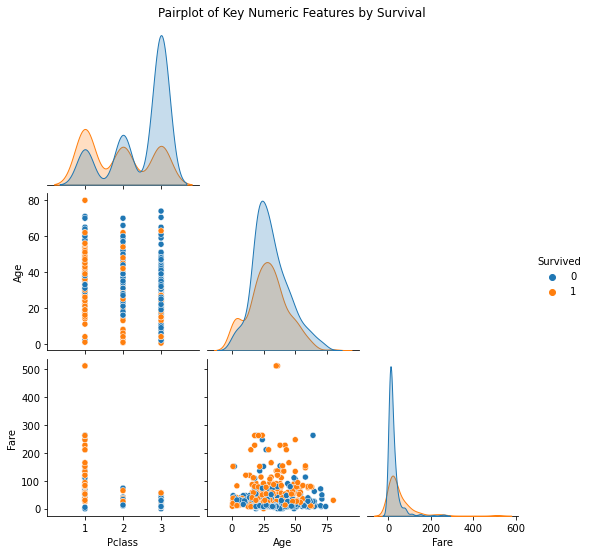

In [3]:
# A. Correlation Heatmap
plt.figure(figsize=(8, 6))
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numeric Features')
plt.tight_layout()
plt.show()

# B. Pairplot colored by Survival
pair_cols = ['Survived', 'Pclass', 'Age', 'Fare']
g = sns.pairplot(df[pair_cols].dropna(), hue='Survived', diag_kind='kde', corner=True)
g.fig.suptitle('Pairplot of Key Numeric Features by Survival', y=1.02)
plt.show()

In [4]:
# Key group trends
print("Survival Rate by Sex:\n", df.groupby('Sex')['Survived'].mean().round(3))
print("\nSurvival Rate by Passenger Class:\n", df.groupby('Pclass')['Survived'].mean().round(3))

# Anomalies check
print("\nPassengers with $0 Fare:", (df['Fare'] == 0).sum())
print("Extreme High Fare (> $500):", len(df[df['Fare'] > 500]))
print("Missing Age records:", df['Age'].isnull().sum())

Survival Rate by Sex:
 Sex
female    0.742
male      0.189
Name: Survived, dtype: float64

Survival Rate by Passenger Class:
 Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64

Passengers with $0 Fare: 15
Extreme High Fare (> $500): 3
Missing Age records: 177


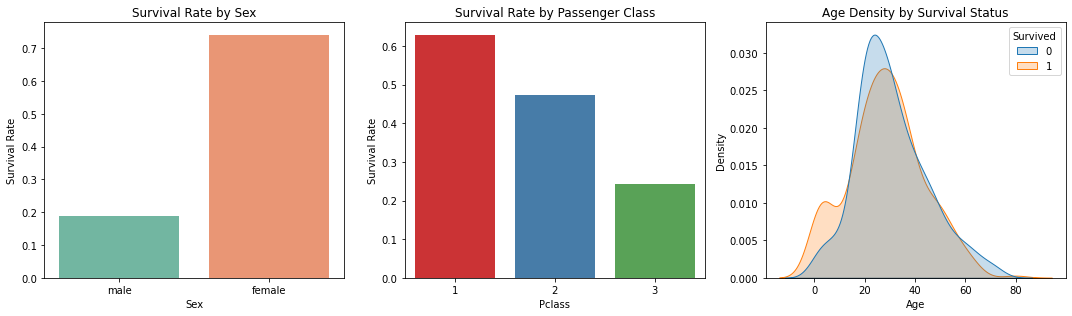

--- Step 5: Feature-Level Inferences ---
• Sex: Females survived at 74.2% vs. Males at 18.9%.
• Pclass: 1st Class survival (63.0%) is >2.5x higher than 3rd Class (24.2%).
• Age: Children (<10 yrs) had a 61.3% survival rate vs. 38.7% for ages 10+.
• Fare: Survivors paid a median fare of $26.00 vs. $10.50 for non-survivors.
• Family: Solo travelers survived at 30.4% vs. 50.6% for those with family.


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Visual verification of top survival drivers (Sex, Pclass, Age)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.barplot(x='Sex', y='Survived', data=df, ax=axes[0], palette='Set2', ci=None)
axes[0].set_title('Survival Rate by Sex')
axes[0].set_ylabel('Survival Rate')

sns.barplot(x='Pclass', y='Survived', data=df, ax=axes[1], palette='Set1', ci=None)
axes[1].set_title('Survival Rate by Passenger Class')
axes[1].set_ylabel('Survival Rate')

sns.kdeplot(data=df, x='Age', hue='Survived', fill=True, ax=axes[2], common_norm=False)
axes[2].set_title('Age Density by Survival Status')

plt.tight_layout()
plt.show()

# 2. Programmatic Feature-Level Inferences Report
inferences = {
    "Sex": f"Females survived at {df[df['Sex']=='female']['Survived'].mean():.1%} vs. Males at {df[df['Sex']=='male']['Survived'].mean():.1%}.",
    "Pclass": f"1st Class survival ({df[df['Pclass']==1]['Survived'].mean():.1%}) is >2.5x higher than 3rd Class ({df[df['Pclass']==3]['Survived'].mean():.1%}).",
    "Age": f"Children (<10 yrs) had a {df[df['Age']<10]['Survived'].mean():.1%} survival rate vs. {df[df['Age']>=10]['Survived'].mean():.1%} for ages 10+.",
    "Fare": f"Survivors paid a median fare of ${df[df['Survived']==1]['Fare'].median():.2f} vs. ${df[df['Survived']==0]['Fare'].median():.2f} for non-survivors.",
    "Family": f"Solo travelers survived at {df[(df['SibSp']+df['Parch'])==0]['Survived'].mean():.1%} vs. {df[(df['SibSp']+df['Parch'])>0]['Survived'].mean():.1%} for those with family."
}

print("--- Step 5: Feature-Level Inferences ---")
for feature, takeaway in inferences.items():
    print(f"• {feature}: {takeaway}")